# EDA: Sentiment Labelled Sentences

In [1]:
from pathlib import Path
import re
import unicodedata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.decomposition import TruncatedSVD
from sklearn.manifold import TSNE
from sklearn.model_selection import train_test_split

ROOT = Path.cwd()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
DATA = ROOT / 'data/raw/sentiment/sentiment labelled sentences'
OUTPUT = ROOT / 'data/processed'
OUTPUT.mkdir(parents=True, exist_ok=True)
SEED = 42
pd.set_option('display.max_colwidth', 150)
plt.rcParams.update({'figure.figsize': (10, 4), 'figure.dpi': 100})
assert DATA.exists(), f'Не найдены исходные TXT: {DATA}'

## 1. Структура файлов, кодировка и типы

Читаем UTF-8 строго, делим строки только по LF и отделяем метку последней табуляцией. Кавычки оставляем в тексте.

In [2]:
files = {'amazon': 'amazon_cells_labelled.txt', 'imdb': 'imdb_labelled.txt', 'yelp': 'yelp_labelled.txt'}
rows, file_info, malformed = [], [], []
for source, filename in files.items():
    text = (DATA / filename).read_bytes().decode('utf-8', errors='strict')
    lines = [line for line in text.split('\n') if line.strip()]
    file_info.append({'source': source, 'file': filename, 'encoding': 'UTF-8', 'rows': len(lines)})
    for number, line in enumerate(lines, 1):
        fields = line.rsplit('\t', 1)
        if len(fields) != 2 or fields[1].strip() not in {'0', '1'}:
            malformed.append({'source': source, 'line': number, 'text': line})
            continue
        rows.append({'id': f'{source}_{number:04}', 'source': source, 'text': fields[0], 'label': int(fields[1])})
reviews = pd.DataFrame(rows)
display(pd.DataFrame(file_info))
display(reviews.head())
display(reviews.dtypes.to_frame('dtype'))
assert len(reviews) == 3000

,source,file,encoding,rows
0,amazon,amazon_cells_labelled.txt,UTF-8,1000
1,imdb,imdb_labelled.txt,UTF-8,1000
2,yelp,yelp_labelled.txt,UTF-8,1000


,id,source,text,label
0,amazon_0001,amazon,So there is no way for me to plug it in here in the US unless I go by a converter.,0
1,amazon_0002,amazon,"Good case, Excellent value.",1
2,amazon_0003,amazon,Great for the jawbone.,1
3,amazon_0004,amazon,Tied to charger for conversations lasting more than 45 minutes.MAJOR PROBLEMS!!,0
4,amazon_0005,amazon,The mic is great.,1


,dtype
id,object
source,object
text,object
label,int64


Получено 3000 отзывов, по 1000 на источник. Поля `text` и `source` строковые, `label` — целое; заголовков в TXT нет.

## 2. Метки и их соответствие тексту

Проверяем допустимые метки и читаем небольшой воспроизводимый пример из каждой пары источник × метка.

In [3]:
display(reviews.label.value_counts().sort_index().rename_axis('label').to_frame('count'))
assert set(reviews.label.unique()) == {0, 1}
sample = reviews.groupby(['source', 'label'], group_keys=False).sample(n=2, random_state=SEED)
display(sample[['id', 'source', 'label', 'text']])

,count
label,
0,1500
1,1500


,id,source,label,text
743,amazon_0744,amazon,0,"Bought mainly for the charger, which broke soon after purchasing."
151,amazon_0152,amazon,0,"Audio Quality is poor, very poor."
592,amazon_0593,amazon,1,THey are so cool!
882,amazon_0883,amazon,1,The only good thing was that it fits comfortably on small ears.
1197,imdb_0198,imdb,0,This movie is BAD.
1488,imdb_0489,imdb,0,"I particularly remember my senses being assaulted by strident cords of music that would blare out with very little warning, and even less meaning."
1449,imdb_0450,imdb,1,"I won't say any more - I don't like spoilers, so I don't want to be one, but I believe this film is worth your time."
1694,imdb_0695,imdb,1,You wont regret it!
2969,yelp_0970,yelp,0,"I don't know what the big deal is about this place, but I won't be back ""ya'all""."
2060,yelp_0061,yelp,0,At least think to refill my water before I struggle to wave you over for 10 minutes.


## 3. Число записей по классам и источникам

Считаем абсолютные частоты.

In [4]:
class_counts = reviews.label.value_counts().sort_index()
source_counts = pd.crosstab(reviews.source, reviews.label)
display(class_counts.to_frame('reviews'))
display(source_counts)

,reviews
label,
0,1500
1,1500


label,0,1
source,,
amazon,500,500
imdb,500,500
yelp,500,500


Оба класса содержат по 1500 записей. В каждом источнике — по 500 отрицательных и положительных отзывов.

## 4. Распределение классов

Строим общий баланс и баланс внутри каждого источника.

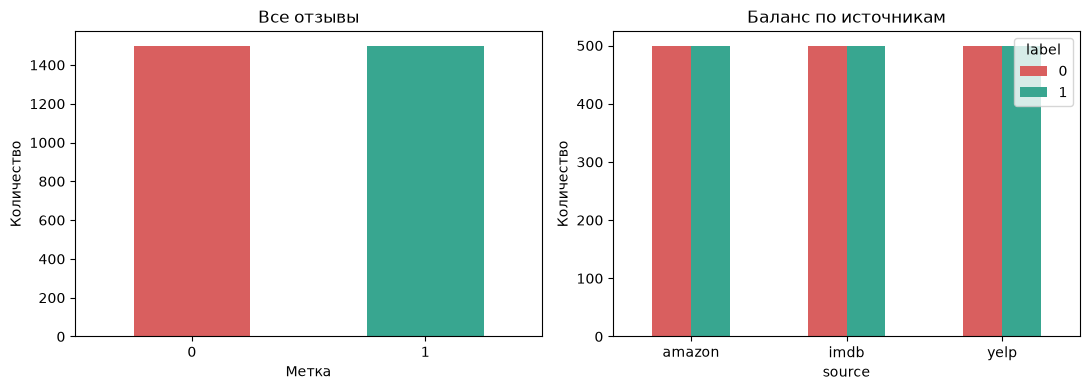

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
class_counts.plot.bar(ax=axes[0], color=['#d95f5f', '#38a690'], rot=0)
axes[0].set(title='Все отзывы', xlabel='Метка', ylabel='Количество')
source_counts.plot.bar(ax=axes[1], rot=0, color=['#d95f5f', '#38a690'])
axes[1].set(title='Баланс по источникам', ylabel='Количество')
plt.tight_layout()
plt.show()

Дисбаланса меток нет ни в целом, ни внутри доменов. Баланс отражает способ отбора набора, а не реальную долю положительных отзывов.

## 5. Пропуски, пустые и некорректные записи


In [6]:
quality = pd.Series({
    'missing_text': reviews.text.isna().sum(),
    'empty_text': reviews.text.str.strip().eq('').sum(),
    'malformed_records': len(malformed),
    'records_with_NEL': reviews.text.str.contains('\x85', regex=False).sum(),
})
display(quality.to_frame('count'))
display(reviews[reviews.text.str.contains('\x85', regex=False)][['id', 'text']])

,count
missing_text,0
empty_text,0
malformed_records,0
records_with_NEL,2


,id,text
1178,imdb_0179,The script is was there a script?
1967,imdb_0968,Definitely worth seeing it's the sort of thought provoking film that forces you to question your own threshold of loneliness.


Пропусков, пустых и некорректных строк нет. В двух отзывах IMDb есть NEL (U+0085); он остаётся частью отзыва. Метод `splitlines()` мог бы ошибочно разделить эти записи.

## 6. Точные дубликаты

Сравниваем исходное текстовое поле, включая пробелы.

In [7]:
exact_duplicates = reviews[reviews.duplicated('text', keep=False)].sort_values('text')
exact_groups = exact_duplicates.groupby('text').size()
display(pd.Series({'groups': len(exact_groups), 'rows': len(exact_duplicates),
                   'redundant_rows': reviews.duplicated('text').sum()}).to_frame('count'))
display(exact_duplicates[['id', 'source', 'label', 'text']].head(10))

,count
groups,17
rows,34
redundant_rows,17


,id,source,label,text
1788,imdb_0789,imdb,1,10/10
1125,imdb_0126,imdb,1,10/10
1363,imdb_0364,imdb,1,Definitely worth checking out.
1090,imdb_0091,imdb,1,Definitely worth checking out.
748,amazon_0749,amazon,0,Does not fit.
446,amazon_0447,amazon,0,Does not fit.
180,amazon_0181,amazon,0,Don't buy this product.
543,amazon_0544,amazon,0,Don't buy this product.
402,amazon_0403,amazon,1,Excellent product for the price.
892,amazon_0893,amazon,1,Excellent product for the price.


Найдено 17 групп точных повторов: 34 строки, из которых 17 лишние. Их нельзя независимо распределять между выборками.

## 7. Дубликаты после нормализации

Нормализованный ключ используется для дедупликации, исходный текст сохраняется.

In [8]:
def normalize_text(text):
    text = unicodedata.normalize('NFC', text).casefold()
    text = ''.join(' ' if unicodedata.category(char).startswith('P') else char for char in text)
    return ' '.join(text.split())

reviews['normalized'] = reviews.text.map(normalize_text)
normalized_duplicates = reviews[reviews.duplicated('normalized', keep=False)].sort_values('normalized')
display(pd.Series({'groups': normalized_duplicates.normalized.nunique(),
                   'rows': len(normalized_duplicates),
                   'redundant_rows': reviews.duplicated('normalized').sum()}).to_frame('count'))
display(normalized_duplicates[['id', 'text', 'normalized']].head(10))

,count
groups,21
rows,49
redundant_rows,28


,id,text,normalized
1125,imdb_0126,10/10,10 10
1788,imdb_0789,10/10,10 10
1626,imdb_0627,Avoid at all costs.,avoid at all costs
1801,imdb_0802,Avoid at ALL costs!,avoid at all costs
1090,imdb_0091,Definitely worth checking out.,definitely worth checking out
1363,imdb_0364,Definitely worth checking out.,definitely worth checking out
993,amazon_0994,disappointed.,disappointed
463,amazon_0464,Disappointed!.,disappointed
748,amazon_0749,Does not fit.,does not fit
446,amazon_0447,Does not fit.,does not fit


После приведения регистра, пробелов и пунктуации найдено 21 повторяющееся значение: 49 строк и 28 лишних записей. Остаётся 2972 уникальных отзыва.

## 8. Одинаковые тексты с разными метками

Ищем противоречия по нормализованному ключу.

In [9]:
label_counts = reviews.groupby('normalized').label.nunique()
conflicting_keys = set(label_counts[label_counts > 1].index)
conflicts = reviews[reviews.normalized.isin(conflicting_keys)]
display(conflicts[['id', 'label', 'text']])
print('Групп с противоречащими метками:', len(conflicting_keys))

,id,label,text


Групп с противоречащими метками: 0


Противоречащих меток у одинаковых нормализованных текстов нет. Возможные ошибки отдельных меток эта проверка не выявляет.

## 9. Длина отзывов

Считаем символы и слова; апостроф внутри слова не разделяет его.

In [10]:
reviews['chars'] = reviews.text.str.len()
reviews['words'] = reviews.text.map(lambda text: len(re.findall(r"\b\w+(?:'\w+)?\b", text)))
length_stats = reviews[['chars', 'words']].describe(percentiles=[.01, .05, .25, .5, .75, .95, .99]).T
display(length_stats)

,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
chars,3000.0,65.271333,44.163566,7.0,12.0,17.0,33.0,55.5,88.0,142.0,215.03,479.0
words,3000.0,11.891333,7.955540,1.0,2.0,3.0,6.0,10.0,16.0,26.0,36.00,73.0


Медиана — 10 слов, среднее — 11,89; диапазон — от 1 до 73 слов. Большинство отзывов короткие, но есть заметный правый хвост.

## 10. Длины положительных и отрицательных отзывов

Сравниваем описательные статистики и распределения по меткам.

chars                      words               
            mean median min  max       mean median min max
label                                                     
0      64.887333   56.0   8  321  11.943333   10.5   1  57
1      65.655333   55.0   7  479  11.839333   10.0   1  73

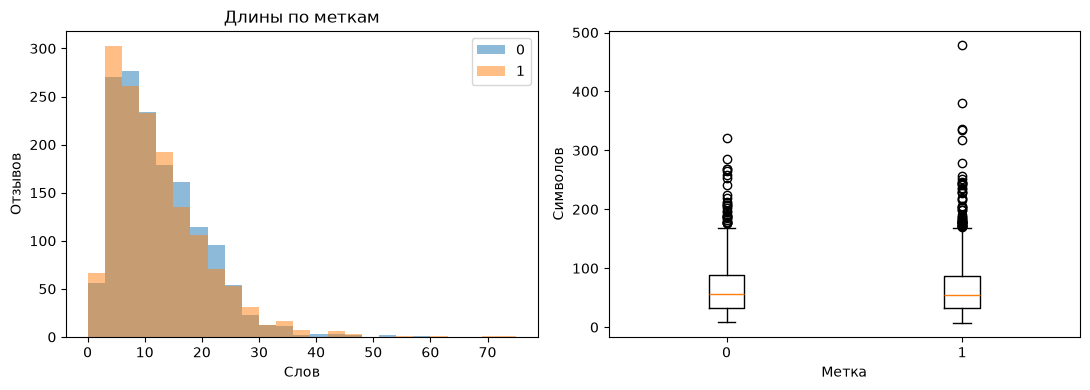

In [11]:
display(reviews.groupby('label')[['chars', 'words']].agg(['mean', 'median', 'min', 'max']))
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for label in [0, 1]:
    axes[0].hist(reviews.loc[reviews.label.eq(label), 'words'], bins=np.arange(0, 77, 3), alpha=.5, label=str(label))
axes[0].set(xlabel='Слов', ylabel='Отзывов', title='Длины по меткам')
axes[0].legend()
axes[1].boxplot([reviews.loc[reviews.label.eq(label), 'chars'] for label in [0, 1]], tick_labels=['0', '1'])
axes[1].set(xlabel='Метка', ylabel='Символов')
plt.tight_layout()
plt.show()

Распределения длин двух классов сильно перекрываются. Одной длины отзыва недостаточно для определения тональности.

## 11. Частотные и характерные слова

Для описания словаря удаляем английские стоп-слова. Характерность — логарифм отношения сглаженных частот класса к другому классу (+1); минимум 5 документов для вывода.

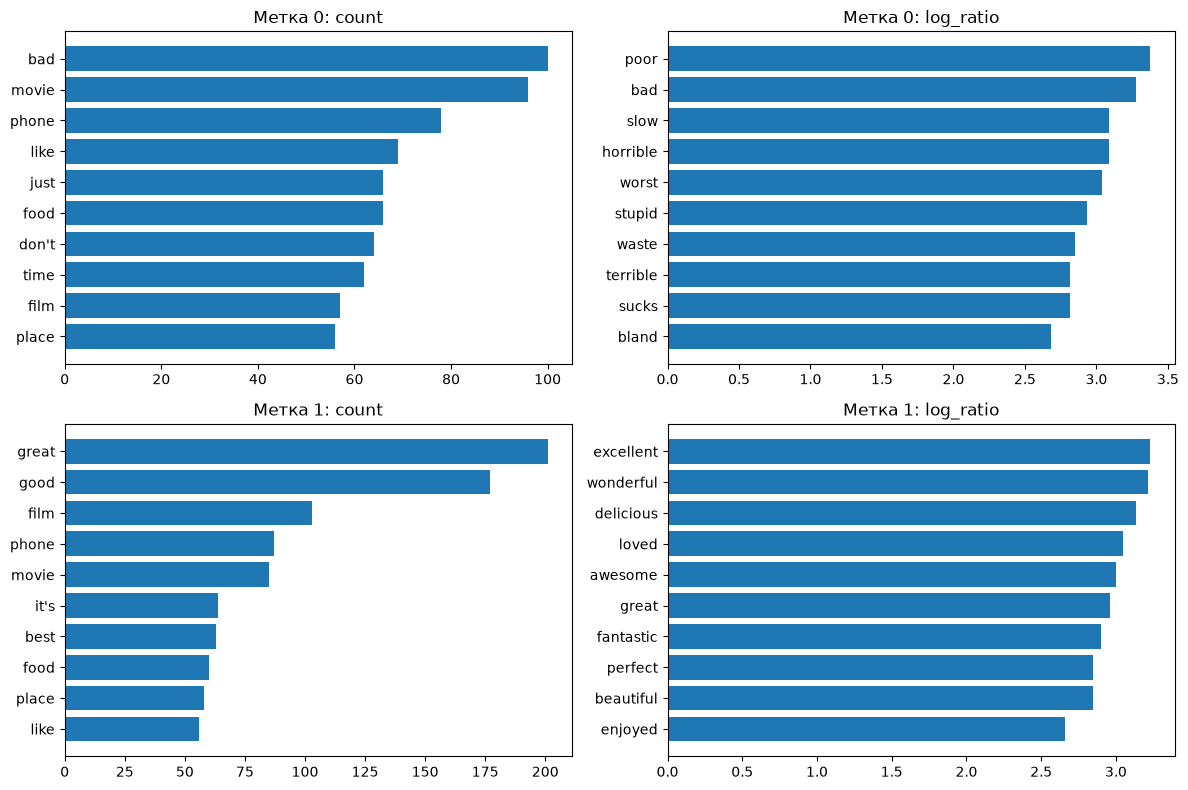

In [12]:
vectorizer = CountVectorizer(stop_words='english', min_df=2, token_pattern=r"(?u)\b[a-zA-Z][a-zA-Z']+\b")
counts = vectorizer.fit_transform(reviews.text)
vocabulary = vectorizer.get_feature_names_out()
word_tables = {}
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for label in [0, 1]:
    selected = reviews.label.eq(label).to_numpy()
    own = np.asarray(counts[selected].sum(axis=0)).ravel()
    other = np.asarray(counts[~selected].sum(axis=0)).ravel()
    document_frequency = np.asarray((counts[selected] > 0).sum(axis=0)).ravel()
    log_ratio = np.log((own + 1) / (own.sum() + len(vocabulary))) - np.log((other + 1) / (other.sum() + len(vocabulary)))
    stats = pd.DataFrame({'word': vocabulary, 'count': own, 'documents': document_frequency, 'log_ratio': log_ratio})
    word_tables[label] = stats
    for column, metric in enumerate(['count', 'log_ratio']):
        top = stats[stats.documents >= 5].nlargest(10, metric).sort_values(metric)
        axes[label, column].barh(top.word, top[metric])
        axes[label, column].set_title(f'Метка {label}: {metric}')
plt.tight_layout()
plt.show()

Для отрицательных отзывов характерны `poor`, `bad`, `horrible`, для положительных — `excellent`, `wonderful`, `delicious`. Предметные слова вроде `phone` и `food` отражают домен, а не только тональность.

## 12. TF-IDF и t-SNE

Сначала уменьшаем размерность TF-IDF до 50 компонент SVD, затем до двух координат t-SNE. Это описательная визуализация всего корпуса.

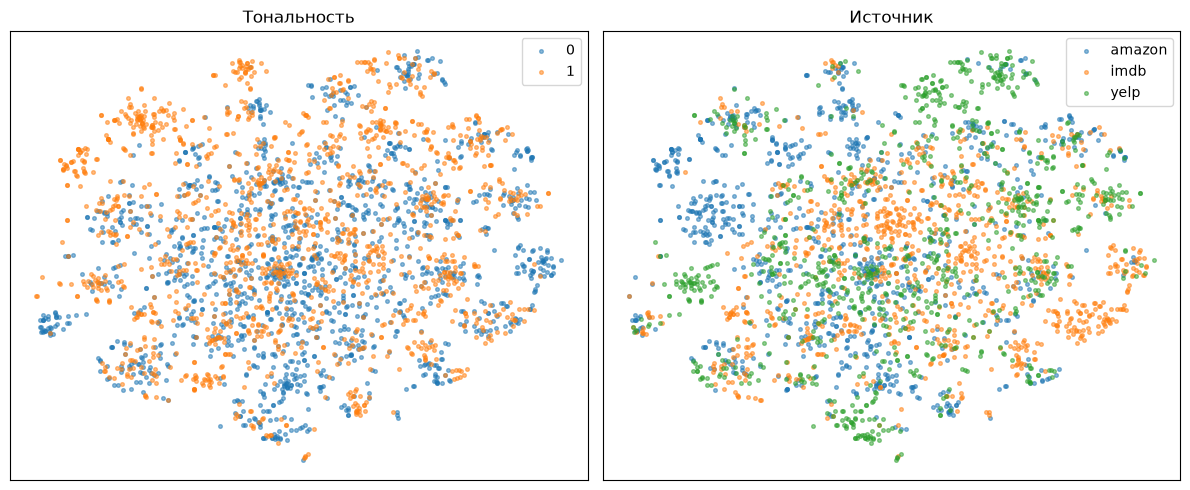

Доля дисперсии SVD: 23.8%


In [13]:
tfidf = TfidfVectorizer(min_df=2, max_df=.98, sublinear_tf=True)
features = tfidf.fit_transform(reviews.text)
svd = TruncatedSVD(n_components=50, random_state=SEED)
reduced = svd.fit_transform(features)
coordinates = TSNE(n_components=2, perplexity=35, init='pca', learning_rate='auto',
                   max_iter=1000, random_state=SEED, n_jobs=2).fit_transform(reduced)
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for label in [0, 1]:
    selected = reviews.label.eq(label)
    axes[0].scatter(coordinates[selected, 0], coordinates[selected, 1], s=7, alpha=.5, label=str(label))
for source in files:
    selected = reviews.source.eq(source)
    axes[1].scatter(coordinates[selected, 0], coordinates[selected, 1], s=7, alpha=.5, label=source)
for ax, title in zip(axes, ['Тональность', 'Источник']):
    ax.set(title=title, xticks=[], yticks=[])
    ax.legend()
plt.tight_layout()
plt.show()
print(f'Доля дисперсии SVD: {svd.explained_variance_ratio_.sum():.1%}')

Видны локальные группы тональности и источников, но классы в целом перемешаны. Проекция не является метрикой качества классификатора. При обучении TF-IDF нужно обучать только на train.

## 13. Положительные, отрицательные и неоднозначные примеры

Сначала показываем примеры обоих классов, затем конкретные кандидаты на неоднозначную или ошибочную метку.

In [14]:
display(reviews.groupby('label', group_keys=False).sample(n=3, random_state=SEED)[['id', 'label', 'text']])
review_ids = ['amazon_0365', 'amazon_0883', 'amazon_0768', 'yelp_0310', 'amazon_0052']
display(reviews[reviews.id.isin(review_ids)][['id', 'label', 'text']])

,id,label,text
2257,yelp_0258,0,I as well would've given godfathers zero stars if possible.
2831,yelp_0832,0,Very poor service.
855,amazon_0856,0,Just does not work.
945,amazon_0946,1,It is easy to turn on and off when you are in the car and the volume controls are quite accessable.
1491,imdb_0492,1,"This movie creates its own universe, and is fascinating in every way."
2063,yelp_0064,1,We'd definitely go back here again.


,id,label,text
51,amazon_0052,1,good protection and does not make phone too bulky.
364,amazon_0365,1,It definitely was not as good as my S11.
767,amazon_0768,0,"I really wanted the Plantronics 510 to be the right one, but it has too many issues for me.The good"
882,amazon_0883,1,The only good thing was that it fits comfortably on small ears.
2309,yelp_0310,1,I did not expect this to be so good!


`amazon_0365` имеет метку 1, хотя сравнение «not as good as my S11» выглядит отрицательным. `amazon_0883` смешивает похвалу с «only good thing», `amazon_0768` обрывается. Отрицание в `yelp_0310` и `amazon_0052` не меняет общий позитивный смысл. Метки автоматически не исправляем.

## 14. Различия между Amazon, IMDb и Yelp

Сравниваем длины и наиболее частые слова каждого источника.

chars          words       
          mean median    mean median
source                              
amazon  55.226   48.0  10.290    9.0
imdb    82.272   68.0  14.478   12.0
yelp    58.316   51.0  10.906   10.0

,Частые слова
amazon,"phone, great, good, product, quality, headset, works, battery, sound, use"
imdb,"movie, film, bad, it's, just, good, like, time, acting, great"
yelp,"food, place, good, service, great, like, time, really, just, best"


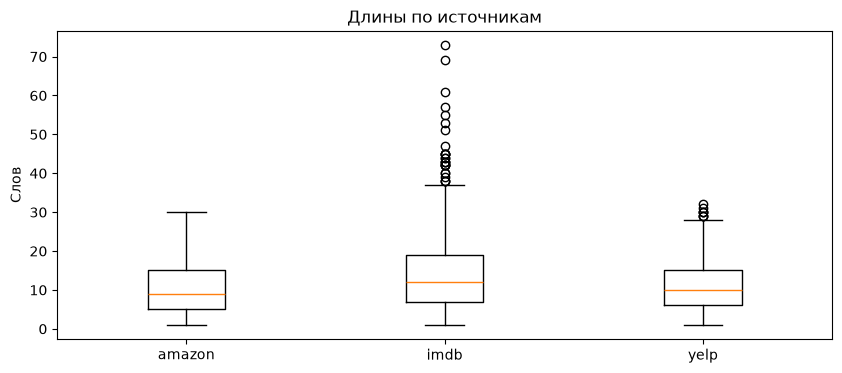

In [15]:
display(reviews.groupby('source')[['chars', 'words']].agg(['mean', 'median']))
source_words = {}
for source in files:
    frequencies = np.asarray(counts[reviews.source.eq(source).to_numpy()].sum(axis=0)).ravel()
    top_indices = frequencies.argsort()[-10:][::-1]
    source_words[source] = ', '.join(vocabulary[top_indices])
display(pd.Series(source_words, name='Частые слова').to_frame())
plt.boxplot([reviews.loc[reviews.source.eq(source), 'words'] for source in files], tick_labels=list(files))
plt.ylabel('Слов')
plt.title('Длины по источникам')
plt.show()

IMDb длиннее: в среднем 14,48 слова против 10,29 у Amazon и 10,91 у Yelp. Домены различаются лексикой: фильмы, устройства и еда/обслуживание. Это потенциальный источник смещения.

## 15. Train, validation и test

Удаляем нормализованные повторы, выбирая первый по source/id. Разделяем 70/15/15 со стратификацией по source × label и seed=42.

In [16]:
clean = reviews[~reviews.normalized.isin(conflicting_keys)].sort_values(['source', 'id']).drop_duplicates('normalized').copy()
train, holdout = train_test_split(clean, test_size=.30, random_state=SEED,
                                 stratify=clean.source + '_' + clean.label.astype(str))
validation, test = train_test_split(holdout, test_size=.50, random_state=SEED,
                                   stratify=holdout.source + '_' + holdout.label.astype(str))
clean['split'] = ''
for name, part in [('train', train), ('validation', validation), ('test', test)]:
    clean.loc[part.index, 'split'] = name
display(clean.split.value_counts())
display(pd.crosstab([clean.split, clean.source], clean.label))

split
train         2080
test           446
validation     446
Name: count, dtype: int64

label                0    1
split      source          
test       amazon   74   74
           imdb     74   75
           yelp     74   75
train      amazon  346  342
           imdb    348  349
           yelp    346  349
validation amazon   74   73
           imdb     75   74
           yelp     75   75

После дедупликации получено 2080 train, 446 validation и 446 test. Баланс меток и доли источников сохранены с точностью до округления.

## 16. Пересечения между выборками

Проверяем нормализованные тексты и сохраняем только необходимые манифесты: уникальные отзывы и связь всех исходных строк с выборками.

In [17]:
text_sets = {name: set(clean.loc[clean.split.eq(name), 'normalized']) for name in ['train', 'validation', 'test']}
for first, second in [('train', 'validation'), ('train', 'test'), ('validation', 'test')]:
    overlap = text_sets[first] & text_sets[second]
    print(f'{first} / {second}: {len(overlap)} пересечений')
    assert not overlap
assert clean.normalized.is_unique
reviews['split'] = reviews.normalized.map(clean.set_index('normalized')['split']).fillna('excluded_conflict')
clean.to_csv(OUTPUT / 'sentiment_splits.csv', index=False)
reviews.to_csv(OUTPUT / 'sentiment_all_rows.csv', index=False)

train / validation: 0 пересечений
train / test: 0 пересечений
validation / test: 0 пересечений


Пересечений по нормализованным текстам нет. Повторы исходных отзывов привязаны к одной выборке; манифесты сохранены в `data/processed/`.

## 17. Очистка, ограничения и смещения

Правила дальнейшей подготовки:

- Сохранять исходный текст, отрицания, апострофы и эмоциональную пунктуацию. Для входа модели достаточно свёртки пробелов/NEL; более агрессивная нормализация здесь служит ключом дедупликации.
- Не исправлять подозрительные метки без проверки контекста. Учитывать обрезанные и очень короткие отзывы.
- Обучать словарь/IDF только на train; выполнять аугментации после разбиения и только в train.
- Данные английские, короткие, заранее отобраны как полярные; нейтрального класса нет. Искусственный баланс отличается от реального.
- Стратифицированное разбиение оценивает смесь знакомых доменов. Перенос на новый домен требует отдельной проверки с исключённым источником.